In [10]:
import numpy as np

from sklearn.datasets import make_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

In [3]:
X,y = make_regression(n_samples=100, n_features=1, n_informative=1, n_targets=1,noise=20,random_state=13)


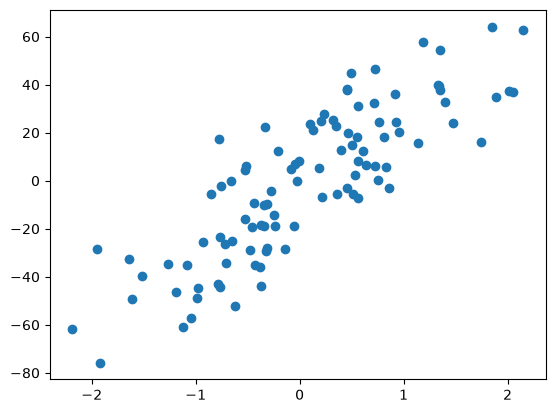

In [4]:
plt.scatter(X,y)

In [5]:
lr = LinearRegression()

In [6]:
lr

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [8]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [9]:
lr.fit(X_train,y_train)
print(lr.coef_)
print(lr.intercept_)

[28.12597332]
-2.2710144261783825


In [11]:
y_pred = lr.predict(X_test)
r2_score(y_test,y_pred)

0.6345158782661012

In [159]:

import numpy as np
import matplotlib.pyplot as plt

class GradientDescentAlgorithm:

    def __init__(self, lr_rate, epochs):
        self.m = 0
        self.b = 0
        self.lr = lr_rate
        self.epochs = epochs
        self.m_history = []
        self.b_history = []

    def fit(self, X, y):
        X = np.asarray(X).ravel()
        y = np.asarray(y).ravel()

        if len(X) != len(y):
            raise ValueError("X and y must contain the same number of values.")

        for i in range(self.epochs):
            error = y - (self.m * X + self.b)

            loss_slope_b = -2 * np.sum(error)
            loss_slope_m = -2 * np.sum(error * X)

            self.b -= self.lr * loss_slope_b
            self.m -= self.lr * loss_slope_m
            
            self.m_history.append(self.m)
            self.b_history.append(self.b)

        print(f"coeff_={self.m}, intercept_={self.b}")

    def predict(self, X):
        X_flat = np.asarray(X).ravel()
        return self.m * X_flat + self.b

    def plot(self, X, y):
        X = np.asarray(X).ravel()
        y = np.asarray(y).ravel()
    
        if len(X) != len(y):
            raise ValueError("X and y must contain the same number of values.")
    
        order = np.argsort(X)
        X_sorted = X[order]
    
        plt.figure(figsize=(10, 6))
        plt.scatter(X, y, color="black", label="Training data")
    
        for i, (m, b) in enumerate(
            zip(self.m_history, self.b_history)
        ):
            y_pred = m * X_sorted + b
    
            plt.plot(
                X_sorted,
                y_pred,
                label=f"Epoch {i+1}: m={m:.2f}, b={b:.2f}"
            )
    
        plt.xlabel("X")
        plt.ylabel("y")
        plt.title("Regression Line for Every m and b Update")
        plt.show()

In [160]:
gd = GradientDescentAlgorithm(lr_rate=0.01, epochs=1000)

In [161]:
gd.fit(X_train,y_train)

coeff_=28.12597331513561, intercept_=-2.271014426178381


In [162]:
gd_y_pred  = gd.predict(X_test)

In [163]:
r2_score(y_test,gd_y_pred)

0.6345158782661012

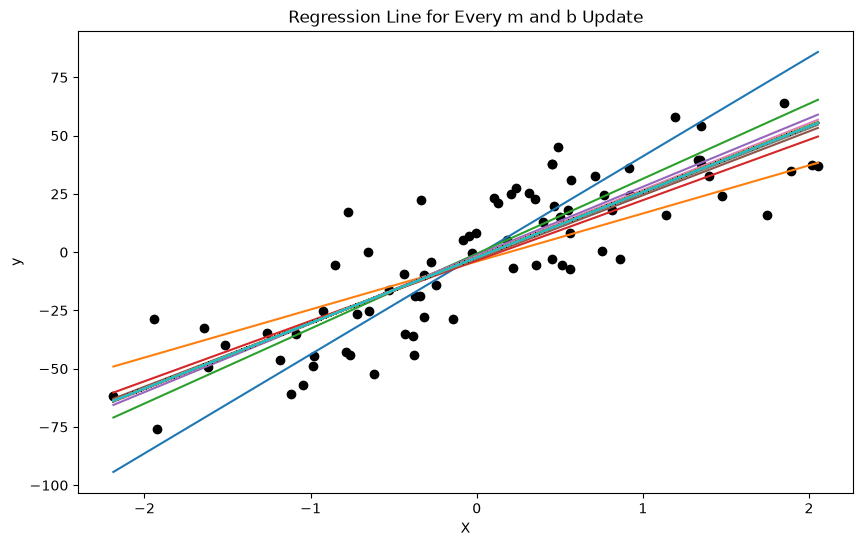

In [164]:
gd.plot(X_train, y_train)